# Neuron Migration - Visualisations (t6)

Two pictures that make the hidden rules visible:

1. **Differences over time per system era.** What happens if we ignore that Neuron was two systems? We run the same
   code with the Neuron NG rules for every year and plot the share of wrong values per year, next to our rules.
2. **Waterfall of an annual statement.** Where the charges of one year come from, step by step.

The plotting functions are in `tools/visuals.py` and work for any task.

# Import libraries

In [1]:
import sys
import pathlib
import pandas as pd

sys.path.insert(0, '..')
sys.path.insert(0, '../../../research')
sys.path.insert(0, '../..')
from rules import conversion_date, extract_date
from schedule import next_due_dates
from projection import maturity_values
from statement import annual_statements
from tools.visuals import plot_errors_by_era, plot_statement_waterfall, share_wrong_by_year
import t3_engine_check
import scoring

# Hyperparameters

In [2]:
project_folder = pathlib.Path('../../..').resolve()

targets_dir = project_folder / 'targets'

sample_size = len(pd.read_csv(targets_dir / 't2_projected_maturity_value.csv'))  # all train policies

example_policy, example_year = 'BL10000013', 2021

# Differences over time per system era

## The what-if experiment

The code takes the day of the system conversion from the data (the conversion events, type 800). In a copy of the
data we move these events to 1900, so the same code treats every policy as a Neuron NG policy: half-up rounding, age
at the nearest birthday, management charge rate / 12 and anchored due dates in every year. Both versions run on all
train policies.

In [3]:
our_rules, chosen = t3_engine_check.sample_data(sample_size)
ng_rules, _ = t3_engine_check.sample_data(sample_size)
events = ng_rules.table('NREVNT').copy()
events.loc[events.EV_EVTTP == 800, 'EV_EFFDT'] = pd.Timestamp('1900-01-01')
ng_rules.tables['NREVNT'] = events

conversion = conversion_date(our_rules)
print('conversion:', conversion.date(), ' policies:', len(chosen))

conversion: 2007-08-11  policies: 3019


In [4]:
policies = our_rules.table('NRPOLH').groupby('PH_POLNR')
start_year, application_year = policies.PH_BEGDT.min().dt.year, policies.PH_APPDT.min().dt.year
variants = {'Neuron NG rules for all years': ng_rules, 'Our rules (COBOL until the conversion)': our_rules}

def wrong_per_variant(task, calculate, year_of):
    targets = scoring.read_targets(targets_dir, task)
    targets = {key: value for key, value in targets.items() if (key if isinstance(key, str) else key[0]) in chosen}
    flags = {}
    for name, data in variants.items():
        calculated = scoring.normalize(task, calculate(data))
        flags[name] = [calculated.get(key) != value for key, value in targets.items()]
    return [year_of(key) for key in targets], flags

t4_years, t4_wrong = wrong_per_variant('t4_annual_statement', annual_statements, lambda key: key[1])
t2_years, t2_wrong = wrong_per_variant('t2_projected_maturity_value', maturity_values, lambda key: application_year[key])
t1_years, t1_wrong = wrong_per_variant('t1_next_due_dates', lambda data: next_due_dates(data, extract_date(data)),
                                       lambda key: start_year[key[0]])

## The picture

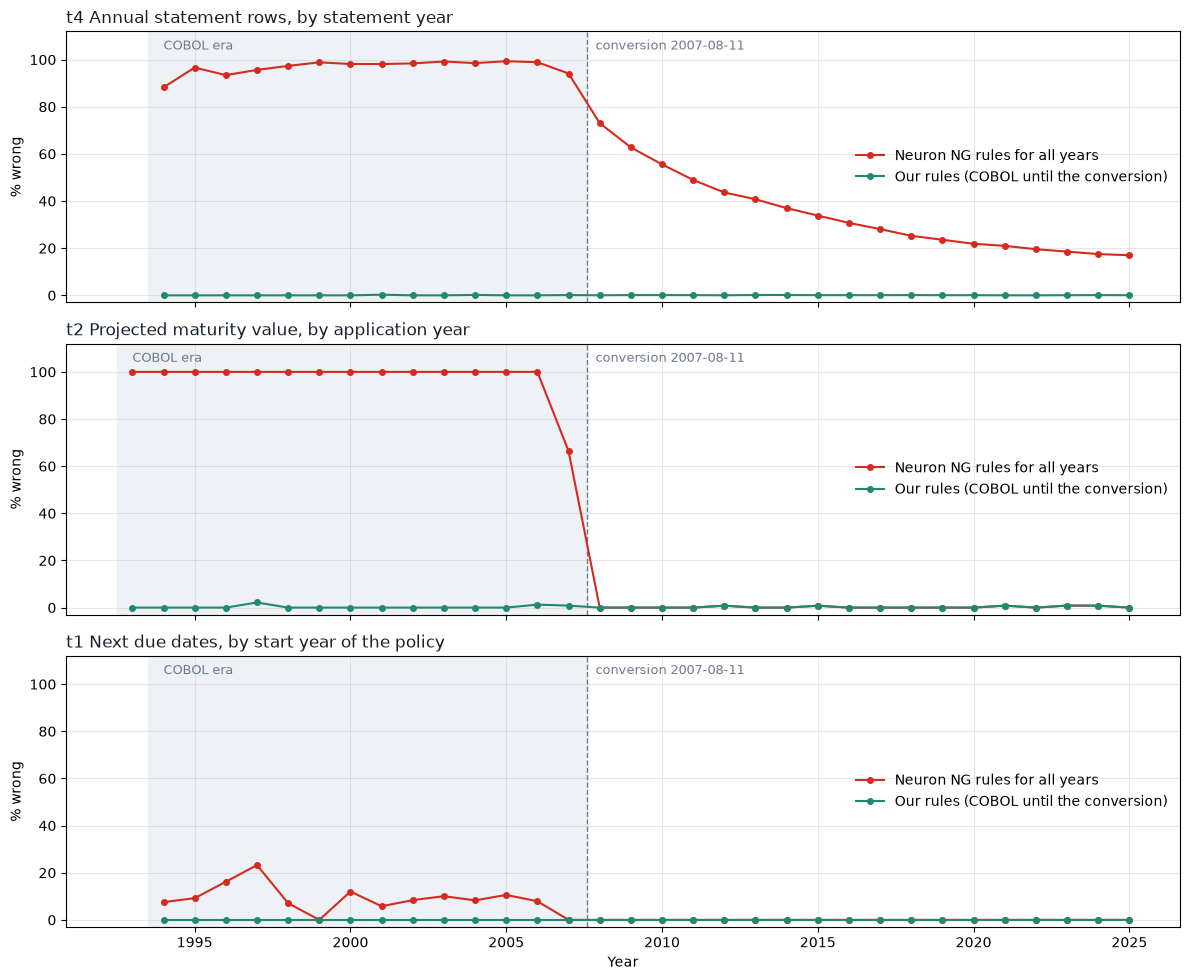

In [5]:
plot_errors_by_era([
    ('t4 Annual statement rows, by statement year', t4_years, t4_wrong),
    ('t2 Projected maturity value, by application year', t2_years, t2_wrong),
    ('t1 Next due dates, by start year of the policy', t1_years, t1_wrong),
], conversion, 'errors_by_era.png')

In [6]:
summary = []
for task, (years, flags) in {'t4': (t4_years, t4_wrong), 't2': (t2_years, t2_wrong), 't1': (t1_years, t1_wrong)}.items():
    for name, wrong in flags.items():
        share = share_wrong_by_year(years, wrong)
        summary.append({'task': task, 'rules': name, 'wrong before 2007 (%)': round(share[share.index < 2007].mean(), 1),
                        'wrong from 2008 (%)': round(share[share.index >= 2008].mean(), 1), 'wrong values': sum(wrong)})
pd.DataFrame(summary)

,task,rules,wrong before 2007 (%),wrong from 2008 (%),wrong values
0,t4,Neuron NG rules for all years,97.0,34.4,13720
1,t4,Our rules (COBOL until the conversion),0.0,0.1,21
2,t2,Neuron NG rules for all years,100.0,0.2,835
3,t2,Our rules (COBOL until the conversion),0.2,0.2,8
4,t1,Neuron NG rules for all years,9.7,0.0,248
5,t1,Our rules (COBOL until the conversion),0.0,0.0,0


The shares per year are also saved as a table, for the chart of the presentation.

In [7]:
ng, ours = 'Neuron NG rules for all years', 'Our rules (COBOL until the conversion)'
by_year = pd.DataFrame({
    't4 statements, Neuron NG rules for all years': share_wrong_by_year(t4_years, t4_wrong[ng]),
    't2 offers, Neuron NG rules for all years': share_wrong_by_year(t2_years, t2_wrong[ng]),
    'Our rules, t2 and t4': share_wrong_by_year(t2_years + t4_years, t2_wrong[ours] + t4_wrong[ours]),
}).round(1)
by_year.to_csv(project_folder / 'Plots' / 'errors_by_era.csv', index_label='year')
by_year.tail()

,"t4 statements, Neuron NG rules for all years","t2 offers, Neuron NG rules for all years","Our rules, t2 and t4"
2021,21.0,0.8,0.0
2022,19.6,0.0,0.0
2023,18.5,0.9,0.1
2024,17.5,0.8,0.1
2025,17.0,0.0,0.0


What the picture shows:

- **t2 projections**: with the Neuron NG rules every offer of the COBOL era is wrong, and every later offer is right.
  The step sits exactly at the conversion.
- **t4 statements**: almost every statement year of the COBOL era is wrong, and the errors do **not** stop at the
  conversion. They fade slowly, because policies that started under COBOL carry the wrong balance into every later
  year. Only the era rules fix both parts.
- **t1 due dates**: only policies that start on the 29th to 31st are affected, so the red line jumps in the few years
  with such COBOL policies.
- The few points of the green line above 0 are manual corrections (t5), not rule errors.

This is the kind of picture that points to a hidden rule: a sudden step in the share of errors at one date.

# Waterfall of an annual statement

The annual statement of policy BL10000013 for 2021, as our rules calculate it (it is identical to Neuron's). The
charges are added up step by step: the entry charge on the premiums invested, the monthly admin fees, the management
charge on the fund value and the risk charge for the death benefit.

calculated: ['2835.00', '103.95', '78.00', '187.88', '69.64', '439.47']
Neuron:     ['2835.00', '103.95', '78.00', '187.88', '69.64', '439.47']


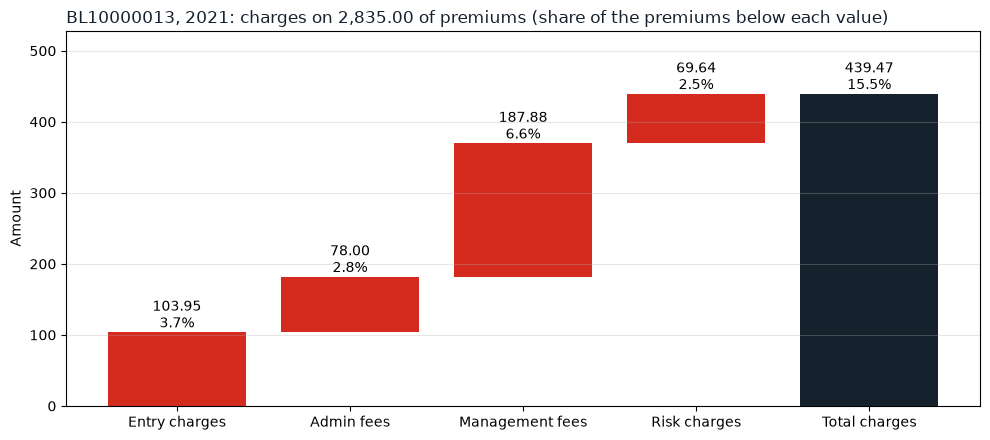

In [8]:
example, _ = t3_engine_check.sample_data(0, policies=[example_policy])
statement = annual_statements(example)[(example_policy, example_year)]
target = scoring.read_targets(targets_dir, 't4_annual_statement')[(example_policy, example_year)]
print('calculated:', [str(value) for value in statement])
print('Neuron:    ', [str(value) for value in target])
plot_statement_waterfall(statement, f'{example_policy}, {example_year}', f'statement_waterfall_{example_policy}_{example_year}.png')

In 2021 the policy paid 2,835.00 of premiums and 439.47 of charges (15.5 %). The management charge is the largest part
and grows every year with the fund value, while the entry charge fell in July 2021, when the entry charge of the
broker's tier went down from 4 % to 3 %.